# Multi-Agent Retrieval for Multi-Hop QA (2WikiMultiHopQA)

Planner -> {Hybrid BM25+FAISS, Wikipedia, Graph RAG} -> Verifier -> (Conflict agent + 1 retry) -> Synthesis.
All agents share one generator: **Qwen3-4B-Instruct-2507 (4-bit)**. Runtime: Colab **T4 GPU**.

Runs are resumable: every answered question is appended to `results/*.jsonl`, so if Colab disconnects just re-run the cell.

## 1. Setup

In [9]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q -U bitsandbytes rank-bm25 faiss-cpu sentence-transformers datasets
!python -m spacy download en_core_web_sm -q

name, memory.total [MiB]
Tesla T4, 15360 MiB
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
autogluon-multimodal 1.5.0 requires nvidia-ml-py3<8.0,>=7.352.0, which is not installed.
autogluon-timeseries 1.5.0 requires chronos-forecasting<2.4,>=2.2.2, which is not installed.
autogluon-timeseries 1.5.0 requires einops<1,>=0.7, which is not installed.
autogluon-timeseries 1.5.0 requires peft<0.18,>=0.13.0, which is not installed.
sagemaker-studio 1.1.32 requires pymongo-auth-aws>=1.3.0, which is not installed.
sagemaker-studio 1.1.32 requires pymongosql>=0.7.2, which is not installed.
autogluon-common 1.5.0 requires pyarrow<21.0.0,>=7.0.0, but you have pyarrow 26.0.0 which is incompatible.
autogluon-multimodal 1.5.0 requires fsspec[http]<=2025.3, but you have fsspec 2026.7.0 which is incompatible.
autogluon-multimodal 1.5.0 requires transformers[sentencepiece]<4.5

Put the project folder on Google Drive (e.g. `MyDrive/Multi-agent Retrieval`) so caches and results survive disconnects.
Alternatively upload a zip of the project and unzip it to `/content`.

In [2]:
import os
import sys
PROJECT_DIR = '/home/sagemaker-user/Multi-retrieval'  # <- adjust if needed
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
sys.path.insert(0, os.path.join(PROJECT_DIR, 'scripts'))
print(os.listdir('.'))

['requirements.txt', '.gitignore', 'README.md', 'notebooks', '.ipynb_checkpoints', 'cache_smoke', 'multiagent_rag', 'cache', 'script', 'results']


In [6]:
pip install --upgrade numpy

  Using cached numpy-2.5.4-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (16.7 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
autogluon-multimodal 1.5.0 requires nvidia-ml-py3<8.0,>=7.352.0, which is not installed.
autogluon-timeseries 1.5.0 requires chronos-forecasting<2.4,>=2.2.2, which is not installed.
autogluon-timeseries 1.5.0 requires einops<1,>=0.7, which is not installed.
autogluon-timeseries 1.5.0 requires peft<0.18,>=0.13.0, which is not installed.
sagemaker-studio 1.1.32 requires pymongo-auth-aws>=1.3.0, which is not installed.
sagemaker-studio 1.1.32 requires pymongosql>=0.7.2, wh

## 2. Data + retrievers
100 dev / 500 eval questions sampled (seed 42) from the 2Wiki validation split. The local corpus is the union of the
context paragraphs of those questions plus 1,000 extra distractor questions (~16k paragraphs).

In [9]:
from multiagent_rag.config import Config
from multiagent_rag.builder import Components

cfg = Config()
comps = Components(cfg)
for name in cfg.enabled_sources:
    comps.retriever(name)  # builds BM25/FAISS index and the knowledge graph (cached to ./cache)
g = comps.retriever('graph').graph
print('graph:', g.number_of_nodes(), 'nodes,', g.number_of_edges(), 'edges')

[data] dev=100 eval=500 corpus=9561 docs


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

graph: 59826 nodes, 101512 edges


### 2a. Retrieval-only analysis (no LLM)
Supporting-page recall of each retriever when queried with the full question, and BM25 vs dense vs RRF fusion.

In [10]:
import pandas as pd
from multiagent_rag.metrics import title_recall

hyb = comps.retriever('hybrid')
rows = []
for ex in comps.data.dev:
    r = {'type': ex.type}
    r['bm25@5'] = title_recall(ex.supporting_titles, [hyb.docs[i].title for i in hyb.bm25_search(ex.question, 5)])
    r['dense@5'] = title_recall(ex.supporting_titles, [hyb.docs[i].title for i in hyb.dense_search(ex.question, 5)])
    for name in cfg.enabled_sources:
        r[f'{name}@5'] = title_recall(ex.supporting_titles, [e.title for e in comps.retriever(name).retrieve(ex.question)])
    rows.append(r)
rdf = pd.DataFrame(rows)
display((rdf.drop(columns='type').mean() * 100).round(1).to_frame('recall %'))
display((rdf.groupby('type').mean() * 100).round(1))

[wikipedia] search failed for 'Was Jorge Ledezma or Yuliya Baraley born first?': 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&format=json&generator=search&gsrsearch=Was+Jorge+Ledezma+or+Yuliya+Baraley+born+first%3F&gsrlimit=3&prop=extracts&exintro=1&explaintext=1&exlimit=3&redirects=1
[wikipedia] search failed for "Henry Of Castile The Senator's": 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&format=json&generator=search&gsrsearch=Henry+Of+Castile+The+Senator%27s&gsrlimit=3&prop=extracts&exintro=1&explaintext=1&exlimit=3&redirects=1
[wikipedia] search failed for "Where did Henry Of Castile The Senator's father die?": 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&format=json&generator=search&gsrsearch=Where+did+Henry+Of+Castile+The+Senator%27s+father+die%3F&gsrlimit=3&prop=extracts&exintro=1&explaintext=1&exlimit=3&redirects=1
[wikipedia] search f

,recall %
bm25@5,66.2
dense@5,70.2
hybrid@5,70.0
wikipedia@5,48.0
graph@5,80.0


,bm25@5,dense@5,hybrid@5,wikipedia@5,graph@5
type,,,,,
bridge_comparison,55.2,51.0,56.2,43.8,64.6
comparison,89.6,100.0,95.8,72.9,97.9
compositional,58.1,62.8,61.6,39.5,82.6
inference,72.2,77.8,77.8,33.3,61.1


## 3. Load the generator and inspect a few traces

In [11]:
from multiagent_rag.trace import print_trace

llm = comps.llm  # Qwen3-4B-Instruct-2507, 4-bit NF4
system = comps.system('full')
for ex in comps.data.dev[:3]:
    print_trace(system.answer(ex.question), ex.answer)

No prebuilt binary for CUDA 12.9, loading CUDA 12.8 instead. Set BNB_CUDA_VERSION to override.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

QUESTION   : Which film has the director who died earlier, Max And Helen or Held Einer Nacht?
GOLD       : Held Einer Nacht
PLANNER    : multi_hop -> ['Who directed the film Max And Helen?', 'Who directed the film Held Einer Nacht?', 'When did #1 and #2 die?']
------------------------------------------------------------------------------------------
STEP 1: Who directed the film Max And Helen?
  *[H1] Max and Helen: Max and Helen is a 1990 American drama film directed by Philip Saville and written by Corey Blechman. It is based on the 1982 book" Max and Helen" by Simon Wies...
   [H2] Max Nosseck: Max Nosseck (19 September 1902 – 29 September 1972) was a German film director, actor and screenwriter. Nosseck was born in Nakel, then in Prussia, but now in P...
   [H3] The Crime of Helen Stanley: The Crime of Helen Stanley is a 1934 American Pre- Code crime film directed by D. Ross Lederman. The film is also known as" Murder in the Studio".
   [H4] Far and Away: Far and Away is a 1992 Ame

## 4. Development run (100 questions)
Use this split to tune prompts / settings. Look at failures before touching the evaluation split.

In [15]:
import json
from script.run_eval import run

dev_summary = run(comps, 'dev', 'full', cfg, 'results/dev_full.jsonl')
print(json.dumps(dev_summary['overall'], indent=2))

[run] full on dev: 0 done, 100 to go -> results/dev_full.jsonl


Batches:   0%|          | 0/150 [00:00<?, ?it/s]

  10/100  EM so far 40.0  (38.0s/question)
  20/100  EM so far 40.0  (37.5s/question)
  30/100  EM so far 50.0  (38.4s/question)
[wikipedia] search failed for 'When was Manuel Romero born?': 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&format=json&generator=search&gsrsearch=When+was+Manuel+Romero+born%3F&gsrlimit=3&prop=extracts&exintro=1&explaintext=1&exlimit=3&redirects=1
  40/100  EM so far 55.0  (37.2s/question)
[wikipedia] search failed for 'When was Elmer W. Conti born?': 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&format=json&generator=search&gsrsearch=When+was+Elmer+W.+Conti+born%3F&gsrlimit=3&prop=extracts&exintro=1&explaintext=1&exlimit=3&redirects=1
[wikipedia] search failed for 'When was Franklin Roosevelt Bueres born?': 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&format=json&generator=search&gsrsearch=When+was+Franklin+Roosevelt+

### 4a. Ablations on dev
Each source / the conflict agent is switched off in turn, reusing the loaded model and indexes.

In [19]:
from dataclasses import replace

ablations = {
    'no_wikipedia': replace(cfg, use_wikipedia=False),
    'no_graph': replace(cfg, use_graph=False),
    'no_hybrid': replace(cfg, use_hybrid=False),
    'no_conflict': replace(cfg, use_conflict_agent=False),
}
run(comps, 'dev', 'single_rag', cfg, 'results/dev_single_rag.jsonl')
run(comps, 'dev', 'closed_book', cfg, 'results/dev_closed_book.jsonl')
for tag, acfg in ablations.items():
    run(comps, 'dev', 'full', acfg, f'results/dev_full_{tag}.jsonl')

[run] single_rag on dev: 100 done, 0 to go -> results/dev_single_rag.jsonl
[run] closed_book on dev: 100 done, 0 to go -> results/dev_closed_book.jsonl
[run] full on dev: 100 done, 0 to go -> results/dev_full_no_wikipedia.jsonl
[run] full on dev: 100 done, 0 to go -> results/dev_full_no_graph.jsonl
[run] full on dev: 100 done, 0 to go -> results/dev_full_no_hybrid.jsonl
[run] full on dev: 100 done, 0 to go -> results/dev_full_no_conflict.jsonl


In [12]:
!python script/summarize.py results/dev_closed_book.jsonl results/dev_single_rag.jsonl results/dev_full.jsonl results/dev_full_no_wikipedia.jsonl results/dev_full_no_graph.jsonl results/dev_full_no_hybrid.jsonl results/dev_full_no_conflict.jsonl --out results/dev_report.md

## Overall

| system | n | EM | F1 | Cover | recall_all | recall_hybrid | recall_wikipedia | recall_graph | conflict_rate | retry_rate | EM_when_retried | avg_confidence | avg_llm_calls | avg_latency_s |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| dev_closed_book | 100 | 28.0 | 31.3 | 28.0 | 0.0 |  |  |  |  |  |  |  | 1.0 | 0.7 |
| dev_single_rag | 100 | 39.0 | 43.4 | 43.0 | 70.0 | 70.0 |  |  |  |  |  |  | 1.0 | 7.8 |
| dev_full | 100 | 53.0 | 57.8 | 59.0 | 96.5 | 89.2 | 75.0 | 92.5 | 9.0 | 9.0 | 55.6 | 0.7 | 4.2 | 39.8 |
| dev_full_no_wikipedia | 100 | 45.0 | 52.7 | 51.0 | 95.2 | 87.8 |  | 91.5 | 3.0 | 3.0 | 0.0 | 0.8 | 4.1 | 29.9 |
| dev_full_no_graph | 100 | 41.0 | 46.9 | 47.0 | 90.8 | 88.8 | 75.2 |  | 7.0 | 7.0 | 42.9 | 0.8 | 4.2 | 32.1 |
| dev_full_no_hybrid | 100 | 47.0 | 52.5 | 52.0 | 93.2 |  | 73.8 | 92.0 | 9.0 | 9.0 | 55.6 | 0.8 | 4.2 | 31.5 |
| dev_full_no_conflict | 100 | 53.0 | 57.8 | 59.0 | 96.5 | 89.2 | 75.2 | 92.5 | 9.0 | 0.0 |  | 0.7 | 4.0 | 33.7 |



## 5. Evaluation run (500 questions)
The full system takes roughly 20-30 s/question on a T4, so expect a few hours: run in several sessions (it resumes).

In [13]:
import json
from script.run_eval import run

run(comps, 'eval', 'closed_book', cfg, 'results/eval_closed_book.jsonl')
run(comps, 'eval', 'single_rag', cfg, 'results/eval_single_rag.jsonl')
eval_summary = run(comps, 'eval', 'full', cfg, 'results/eval_full.jsonl')
print(json.dumps(eval_summary['overall'], indent=2))

[run] closed_book on eval: 500 done, 0 to go -> results/eval_closed_book.jsonl
[run] single_rag on eval: 500 done, 0 to go -> results/eval_single_rag.jsonl
[run] full on eval: 367 done, 133 to go -> results/eval_full.jsonl
  10/133  EM so far 50.9  (38.9s/question)
  20/133  EM so far 50.6  (37.3s/question)
  30/133  EM so far 50.6  (36.8s/question)
  40/133  EM so far 49.9  (39.6s/question)


Batches:   0%|          | 0/150 [00:00<?, ?it/s]

  50/133  EM so far 49.4  (38.2s/question)
  60/133  EM so far 48.9  (37.0s/question)
[wikipedia] search failed for 'Marc Sorkin: What are the nationalities of and ?': 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&format=json&generator=search&gsrsearch=Marc+Sorkin%3A+What+are+the+nationalities+of+and+%3F&gsrlimit=3&prop=extracts&exintro=1&explaintext=1&exlimit=3&redirects=1
[wikipedia] search failed for 'Thomas H. Ince: What are the nationalities of and ?': 429 Client Error: Too Many Requests for url: https://en.wikipedia.org/w/api.php?action=query&format=json&generator=search&gsrsearch=Thomas+H.+Ince%3A+What+are+the+nationalities+of+and+%3F&gsrlimit=3&prop=extracts&exintro=1&explaintext=1&exlimit=3&redirects=1
  70/133  EM so far 48.5  (37.0s/question)
  80/133  EM so far 48.5  (35.8s/question)
  90/133  EM so far 47.9  (35.8s/question)
  100/133  EM so far 48.0  (36.3s/question)
[wikipedia] search failed for 'Hurricane At Pilgrim Hill': 

In [3]:
!python script/summarize.py results/eval_closed_book.jsonl results/eval_single_rag.jsonl results/eval_full.jsonl --out results/eval_report.md

## Overall

| system | n | EM | F1 | Cover | recall_all | recall_hybrid | recall_wikipedia | recall_graph | conflict_rate | retry_rate | EM_when_retried | avg_confidence | avg_llm_calls | avg_latency_s |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| eval_closed_book | 500 | 24.2 | 28.5 | 24.6 | 0.0 |  |  |  |  |  |  |  | 1.0 | 0.7 |
| eval_single_rag | 500 | 37.2 | 42.5 | 40.4 | 70.8 | 70.8 |  |  |  |  |  |  | 1.0 | 8.0 |
| eval_full | 500 | 48.4 | 56.4 | 56.4 | 94.3 | 89.1 | 74.5 | 90.8 | 3.8 | 3.8 | 36.8 | 0.8 | 4.1 | 37.0 |

## By question type

| system | type | n | EM | F1 | Cover |
|---|---|---|---|---|---|
| eval_closed_book | bridge_comparison | 96 | 44.8 | 45.7 | 44.8 |
| eval_closed_book | comparison | 120 | 54.2 | 54.8 | 54.2 |
| eval_closed_book | compositional | 211 | 5.2 | 7.4 | 6.2 |
| eval_closed_book | inference | 73 | 2.7 | 23.9 | 2.7 |
| eval_single_rag | bridge_comparison | 96 | 54.2 | 55.7 | 58.3 |
| eval_single_rag | comparison | 120 | 77.5 | 79.

## 6. Charts and error analysis

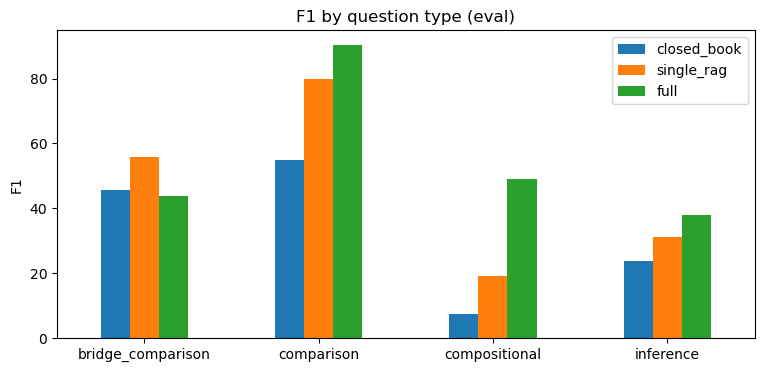

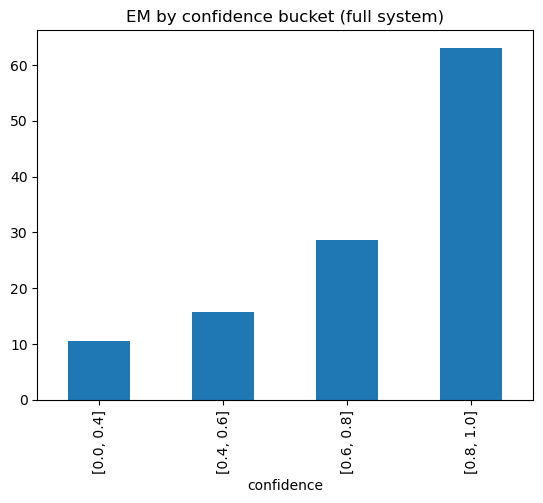

,confidence,n,EM,F1
0,"[0.0, 0.4]",95,10.526316,17.168578
1,"[0.4, 0.6]",19,15.789474,24.210526
2,"[0.6, 0.8]",42,28.571429,44.051742
3,"[0.8, 1.0]",344,63.081395,70.485124


In [15]:
import matplotlib.pyplot as plt
from multiagent_rag.metrics import summarize, calibration_table

def load(path):
    with open(path, encoding='utf-8') as f:
        return [json.loads(l) for l in f if l.strip()]

systems = {n: load(f'results/eval_{n}.jsonl') for n in ['closed_book', 'single_rag', 'full']}
by_type = pd.DataFrame({n: {t: m['F1'] for t, m in summarize(r)['by_type'].items()} for n, r in systems.items()})
by_type.plot.bar(figsize=(9, 4), title='F1 by question type (eval)'); plt.ylabel('F1'); plt.xticks(rotation=0); plt.show()

cal = pd.DataFrame(calibration_table(systems['full']))
cal.plot.bar(x='confidence', y='EM', legend=False, title='EM by confidence bucket (full system)'); plt.show()
display(cal)

In [16]:
full = systems['full']
errors = [r for r in full if r['f1'] < 0.5]
print(f'{len(errors)} / {len(full)} answers with F1 < 0.5')
display(pd.DataFrame([{ 'type': r['type'], 'question': r['question'], 'gold': r['gold'], 'pred': r['pred'],
                        'recall': r['retrieval_recall']['all'], 'conflict': r['conflicts_detected'],
                        'path': ' | '.join(r['reasoning_path']) } for r in errors[:25]]))

209 / 500 answers with F1 < 0.5


,type,question,gold,pred,recall,conflict,path
0,compositional,Where was the place of death of the director o...,New York,Death Valley,1.00,0,Who is the director of film The Lion And The M...
1,inference,Who is Duke Georg Alexander Of Mecklenburg-Str...,Grand Duke Michael Pavlovich of Russia,Duke Georg August of Mecklenburg-Strelitz,0.50,0,Who is the mother of Duke Georg Alexander Of M...
2,bridge_comparison,"Which film has the director died earlier, Self...",Self-Made Maids,Jules White,1.00,0,Who is the director of film Self-Made Maids? -...
3,compositional,Where was the director of film Digna... Hasta ...,France,"Mexico, D.F.",1.00,0,Who is the director of film Digna... Hasta El ...
4,bridge_comparison,Which film has the director who was born earli...,Mumbai Delhi Mumbai,Satish Rajwade,1.00,0,Who is the director of film Sorority Row? -> S...
5,bridge_comparison,"Which film whose director is younger, Many Tan...",Do Musafir,Devendra Goel,1.00,0,Who is the director of film Many Tanks Mr. Atk...
6,inference,Who is the mother-in-law of Blanche Of Navarre...,Alix,Agnes of Beaujeu,0.50,0,Who is the mother-in-law of Blanche Of Navarre...
7,bridge_comparison,Which film has the director who was born first...,Emily Brontë'S Wuthering Heights,Final Destination 3,1.00,0,Who is the director of film Final Destination ...
8,bridge_comparison,Which film has the director who was born first...,The Lunatic At Large,Bat*21,0.75,0,Who is the director of film Bat*21? -> Peter M...
9,bridge_comparison,"Which film whose director was born first, Fles...",Memories Of A Mexican,Flesh And The Spur,1.00,0,When was the director of film Flesh And The Sp...


In [17]:
# Examples where the conflict agent fired: inspect how the retry changed the answer
for r in [r for r in full if r['retries'] > 0][:3]:
    print_trace(r, r['gold'])

QUESTION   : Where did Marie Antoinette Murat's husband die?
GOLD       : Bologna
PLANNER    : multi_hop -> ['Who was the husband of Marie Antoinette Murat?', 'Where did #1 die?']
------------------------------------------------------------------------------------------
STEP 1: Who was the husband of Marie Antoinette Murat?
   [H1] Marie Antoinette Murat: Marie Antoinette Murat, (3 January 1793, Labastide-Murat, Lot, French Republic – 19 January 1847, Sigmaringen, Principality of Hohenzollern-Sigmaringen) was a m...
   [H2] Marie Antoinette: Marie Antoinette (born Maria Antonia Josepha Johanna; 2 November 1755 – 16 October 1793) was the last Queen of France before the French Revolution. She was born...
   [H3] Karl Anton, Prince of Hohenzollern: Prince Karl Anton of Hohenzollern- Sigmaringen( 7 September 1811 – 2 June 1885) was head of the Princely House of Hohenzollern- Sigmaringen, Hohenzollern from 1...
   [H4] Charles Guillaume Le Normant d'Étiolles: Charles- Guillaume Le Normant d

## 7. Ask your own question

In [ ]:
print_trace(system.answer('Where was the director of film The Fascist born?'))

In [7]:
import json
def load(path):
    with open(path, encoding='utf-8') as f:
        return [json.loads(l) for l in f if l.strip()]
systems = {n: load(f'results/eval_{n}.jsonl') for n in ['closed_book', 'single_rag', 'full']}
bc = [r for r in systems['full'] if r['type'] == 'bridge_comparison' and r['em'] == 0]
for r in bc[:10]:
    print(r['question'], '| gold:', r['gold'], '| pred:', r['pred'], '| subqs:', r['sub_questions'])

Which film has the director died earlier, Self-Made Maids or A Day For Lionhearts? | gold: Self-Made Maids | pred: Jules White | subqs: ['Who is the director of film Self-Made Maids?', 'Who is the director of film A Day For Lionhearts?', 'When did #1 and #2 die?']
Which film has the director who was born earlier, Sorority Row or Mumbai Delhi Mumbai? | gold: Mumbai Delhi Mumbai | pred: Satish Rajwade | subqs: ['Who is the director of film Sorority Row?', 'Who is the director of film Mumbai Delhi Mumbai?', 'When was #1 born?']
Which film whose director is younger, Many Tanks Mr. Atkins or Do Musafir? | gold: Do Musafir | pred: Devendra Goel | subqs: ['Who is the director of film Many Tanks Mr. Atkins?', 'Who is the director of film Do Musafir?', 'When was #1 born?']
Which film has the director who was born first, Final Destination 3 or Emily Brontë'S Wuthering Heights? | gold: Emily Brontë'S Wuthering Heights | pred: Final Destination 3 | subqs: ['Who is the director of film Final Destin

In [26]:
"""Notebook-friendly result tables (pandas Styler) for one or more results/*.jsonl files."""
from __future__ import annotations

import json
import os
import re
from typing import Dict, List

import pandas as pd

from multiagent_rag.metrics import calibration_table, normalize_answer, summarize

OVERALL_COLUMNS = {
    "n": "Questions",
    "EM": "EM %",
    "F1": "F1 %",
    "Cover": "Cover %",
    "recall_all": "Recall: all %",
    "recall_hybrid": "Recall: hybrid %",
    "recall_wikipedia": "Recall: Wikipedia %",
    "recall_graph": "Recall: graph %",
    "conflict_rate": "Conflict rate %",
    "retry_rate": "Retry rate %",
    "EM_when_retried": "EM when retried %",
    "avg_confidence": "Avg confidence",
    "avg_llm_calls": "LLM calls / q",
    "avg_latency_s": "Seconds / q",
}
HIGHER_IS_BETTER = ["EM %", "F1 %", "Cover %", "Recall: all %", "Recall: hybrid %", "Recall: Wikipedia %",
                    "Recall: graph %", "EM when retried %"]
LOWER_IS_BETTER = ["LLM calls / q", "Seconds / q"]


def load_records(path: str) -> List[Dict]:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def _name(path: str) -> str:
    name = os.path.basename(path).replace(".jsonl", "")
    for prefix in ("eval_", "dev_"):
        if name.startswith(prefix):
            return name[len(prefix):]
    return name


def overall_frame(paths: List[str]) -> pd.DataFrame:
    rows = {}
    for p in paths:
        rows[_name(p)] = summarize(load_records(p))["overall"]
    df = pd.DataFrame(rows).T
    df = df[[c for c in OVERALL_COLUMNS if c in df.columns]].rename(columns=OVERALL_COLUMNS)
    df.index.name = "System"
    # closed_book retrieves nothing, so its recall is not 0 but "not applicable"
    for col in [c for c in df.columns if c.startswith("Recall")]:
        if "closed_book" in df.index:
            df.loc["closed_book", col] = float("nan")
    return df


def by_type_frame(paths: List[str], metric: str = "EM") -> pd.DataFrame:
    data, counts = {}, {}
    for p in paths:
        s = summarize(load_records(p))["by_type"]
        data[_name(p)] = {t: m[metric] for t, m in s.items()}
        counts.update({t: m["n"] for t, m in s.items()})
    df = pd.DataFrame(data)
    df.insert(0, "Questions", pd.Series(counts))
    df.index.name = "Question type"
    return df


def calibration_frame(path: str) -> pd.DataFrame:
    df = pd.DataFrame(calibration_table(load_records(path)))
    return df.rename(columns={"confidence": "Confidence bucket", "n": "Questions", "EM": "EM %", "F1": "F1 %"}).set_index(
        "Confidence bucket"
    )


def styled_overall(df: pd.DataFrame):
    fmt = {c: "{:.1f}" for c in df.columns}
    fmt.update({"Questions": "{:.0f}", "Avg confidence": "{:.2f}"})
    st = df.style.format(fmt, na_rep="–")
    hi = [c for c in HIGHER_IS_BETTER if c in df.columns]
    lo = [c for c in LOWER_IS_BETTER if c in df.columns]
    if hi:
        st = st.highlight_max(subset=hi, props="font-weight:bold; background-color:#d4edda")
    if lo:
        st = st.highlight_min(subset=lo, props="font-weight:bold; background-color:#d4edda")
    return st


def styled_by_type(df: pd.DataFrame, metric: str):
    systems = [c for c in df.columns if c != "Questions"]
    return (
        df.style.format({**{c: "{:.1f}" for c in systems}, "Questions": "{:.0f}"})
        .background_gradient(subset=systems, cmap="Greens", vmin=0, vmax=100)
        .set_caption(f"{metric} % by question type (darker = better)")
    )


def styled_calibration(df: pd.DataFrame):
    return (
        df.style.format({"Questions": "{:.0f}", "EM %": "{:.1f}", "F1 %": "{:.1f}"})
        .bar(subset=["EM %"], color="#8fd19e", vmin=0, vmax=100)
        .set_caption("Accuracy per confidence bucket (should rise with confidence)")
    )


ERROR_CATEGORIES = [
    "Close but worded differently",
    "Missed evidence",
    "Not one of the offered options",
    "Unresolved source conflict",
    "Reasoning error (evidence found)",
]


_OPTIONS_RE = re.compile(r",\s*([^,]+?)\s+or\s+([^,]+?)\s*\?\s*$")


def _options(question: str) -> List[str]:
    """The two candidates offered by "..., A or B?" questions."""
    m = _OPTIONS_RE.search(question)
    return [m.group(1), m.group(2)] if m else []


def error_category(r: Dict) -> str:
    """Heuristic cause of a wrong answer, checked in priority order."""
    if r.get("cover") or r.get("f1", 0) >= 0.5:
        return ERROR_CATEGORIES[0]
    if r.get("retrieval_recall", {}).get("all", 1.0) < 1.0:
        return ERROR_CATEGORIES[1]
    options = _options(r["question"])
    if options and normalize_answer(r["pred"]) not in {normalize_answer(o) for o in options}:
        return ERROR_CATEGORIES[2]
    if any(st.get("conflict_unresolved") for st in r.get("steps", [])):
        return ERROR_CATEGORIES[3]
    return ERROR_CATEGORIES[4]


def error_breakdown_frame(records: List[Dict]) -> pd.DataFrame:
    wrong = [r for r in records if not r["em"]]
    df = pd.DataFrame([{"type": r["type"], "cause": error_category(r)} for r in wrong])
    table = pd.crosstab(df["type"], df["cause"]).reindex(columns=ERROR_CATEGORIES, fill_value=0)
    table.index.name = "Question type"
    return table


def plot_error_breakdown(records: List[Dict], title: str = "Why answers were wrong (EM = 0), by question type"):
    import matplotlib.pyplot as plt

    table = error_breakdown_frame(records)
    ax = table.plot.barh(stacked=True, figsize=(10, 4), colormap="tab20c")
    ax.set_title(title)
    ax.set_xlabel("Number of wrong answers")
    ax.set_ylabel("Question type")
    ax.legend(title="Likely cause", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
    return table


def show_traces(
    records: List[Dict],
    per_type: int = 2,
    types: List[str] = None,
    correct: bool = None,
    retried: bool = None,
    cause: str = None,
) -> None:
    """Collapsible full agent traces grouped by question type.

    correct: True = only EM-correct answers, False = only wrong ones, None = both.
    retried: True = only questions where the conflict agent ran a retry, False = none, None = both.
    cause:   restrict wrong answers to one of ERROR_CATEGORIES.
    """
    import contextlib
    import html
    import io

    from IPython.display import HTML, Markdown, display

    from multiagent_rag.trace import print_trace

    def keep(r):
        if correct is not None and bool(r["em"]) != correct:
            return False
        if retried is not None and (r.get("retries", 0) > 0) != retried:
            return False
        return cause is None or (not r["em"] and error_category(r) == cause)

    pool = [r for r in records if keep(r)]
    if not pool:
        display(Markdown("_No questions match these filters._"))
        return
    for t in types or sorted({r["type"] for r in pool}):
        sel = [r for r in pool if r["type"] == t][:per_type]
        if not sel:
            continue
        total = sum(1 for r in pool if r["type"] == t)
        display(Markdown(f"#### {t}: showing {len(sel)} of {total}"))
        for r in sel:
            buf = io.StringIO()
            with contextlib.redirect_stdout(buf):
                print_trace(r, r["gold"])
            status = "correct" if r["em"] else error_category(r)
            if r.get("retries", 0) > 0:
                status += " · conflict retry"
            summary = (f"<b>{html.escape(r['question'])}</b><br>gold: <code>{html.escape(r['gold'])}</code> "
                       f"&nbsp; pred: <code>{html.escape(str(r['pred']))}</code> &nbsp; "
                       f"<i>{html.escape(status)}</i>")
            display(HTML(f"<details style='margin:4px 0'><summary>{summary}</summary>"
                         f"<pre style='white-space:pre-wrap;font-size:12px'>{html.escape(buf.getvalue())}</pre>"
                         f"</details>"))


def show_wrong_traces(records: List[Dict], per_type: int = 2, types: List[str] = None, cause: str = None) -> None:
    """Collapsible full agent traces of wrong answers, grouped by question type."""
    show_traces(records, per_type=per_type, types=types, correct=False, cause=cause)


def retry_outcomes(records: List[Dict]) -> pd.DataFrame:
    """For questions where the conflict agent retried: did the retry change the step answer, and was it right?"""
    from multiagent_rag.metrics import answers_compatible

    rows = []
    for r in records:
        for st in r.get("steps", []):
            if not st.get("retried"):
                continue
            before = (st.get("initial_verdict") or {}).get("answer")
            after = st.get("answer")
            rows.append({
                "type": r["type"],
                "question": r["question"],
                "sub-question": st.get("resolved_question"),
                "answer before retry": before,
                "answer after retry": after,
                "changed": not (before and after and answers_compatible(before, after)),
                "still unresolved": bool(st.get("conflict_unresolved")),
                "final correct (EM)": bool(r["em"]),
            })
    return pd.DataFrame(rows)


def show_report(paths: List[str], calibration_of: str = None) -> None:
    """Display overall, per-type and calibration tables in a Jupyter/Colab notebook."""
    from IPython.display import Markdown, display

    display(Markdown("### Overall results"))
    display(styled_overall(overall_frame(paths)))
    for metric in ("EM", "F1"):
        display(Markdown(f"### {metric} by question type"))
        display(styled_by_type(by_type_frame(paths, metric), metric))
    target = calibration_of or next((p for p in paths if _name(p).startswith("full")), None)
    if target:
        display(Markdown(f"### Confidence calibration: `{_name(target)}`"))
        display(styled_calibration(calibration_frame(target)))


In [15]:


show_report(['results/eval_closed_book.jsonl', 'results/eval_single_rag.jsonl', 'results/eval_full.jsonl'])

### Overall results

,Questions,EM %,F1 %,Cover %,Recall: all %,Recall: hybrid %,Recall: Wikipedia %,Recall: graph %,Conflict rate %,Retry rate %,EM when retried %,Avg confidence,LLM calls / q,Seconds / q
System,,,,,,,,,,,,,,
closed_book,500,24.2,28.5,24.6,–,–,–,–,–,–,–,–,1.0,0.7
single_rag,500,37.2,42.5,40.4,70.8,70.8,–,–,–,–,–,–,1.0,8.0
full,500,48.4,56.4,56.4,94.3,89.1,74.5,90.8,3.8,3.8,36.8,0.76,4.1,37.0


### EM by question type

,Questions,closed_book,single_rag,full
Question type,,,,
bridge_comparison,96,44.8,54.2,43.8
comparison,120,54.2,77.5,90.0
compositional,211,5.2,14.7,37.9
inference,73,2.7,13.7,16.4


### F1 by question type

,Questions,closed_book,single_rag,full
Question type,,,,
bridge_comparison,96,45.7,55.7,43.8
comparison,120,54.8,79.7,90.4
compositional,211,7.4,19.2,49.1
inference,73,23.9,31.3,38.1


### Confidence calibration: `full`

,Questions,EM %,F1 %
Confidence bucket,,,
"[0.0, 0.4]",95,10.5,17.2
"[0.4, 0.6]",19,15.8,24.2
"[0.6, 0.8]",42,28.6,44.1
"[0.8, 1.0]",344,63.1,70.5


In [25]:


full = load_records('results/eval_full.jsonl')

show_wrong_traces(full, per_type=3, types=['bridge_comparison'])
show_wrong_traces(full, per_type=1, types=['compositional'])
show_wrong_traces(full, per_type=1, types=['inference'])
show_wrong_traces(full, per_type=1, types=['comparison'])

#### bridge_comparison: 3 wrong answer(s) shown

#### compositional: 1 wrong answer(s) shown

#### inference: 1 wrong answer(s) shown

#### comparison: 1 wrong answer(s) shown

In [28]:
show_traces(full, per_type=10, correct=True, retried=True)   # retries that still ended wrong

#### bridge_comparison: showing 2 of 2

#### comparison: showing 1 of 1

#### compositional: showing 3 of 3

#### inference: showing 1 of 1

In [29]:
show_traces(full, per_type=1, correct=False, retried=True)   # retries that still ended wrong

#### bridge_comparison: showing 1 of 2

#### compositional: showing 1 of 9

#### inference: showing 1 of 1